### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [90]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [91]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [92]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [93]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
    df = pd.DataFrame(np.array(data[1].data).byteswap().newbyteorder()) 
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [94]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [95]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [96]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [97]:
features = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]


In [98]:
target=df['zhelio']

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction][def]

[def]: https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [99]:
model = RandomForestRegressor()

In [100]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [101]:
%%time
scores = cross_validate(model, features, target,
                        cv=KFold(n_splits=5, shuffle=True, random_state=10),
                        return_train_score=True, n_jobs=-1)

CPU times: user 25.7 ms, sys: 78.7 ms, total: 104 ms
Wall time: 7.39 s


In [102]:
scores

{'fit_time': array([6.13627815, 6.052742  , 6.10406089, 6.15255499, 6.16852713]),
 'score_time': array([0.09350586, 0.09350991, 0.09432507, 0.09298301, 0.09240079]),
 'test_score': array([0.30102709, 0.30450873, 0.31835749, 0.30260545, 0.31076742]),
 'train_score': array([0.87281109, 0.87858836, 0.87731689, 0.87664289, 0.87410408])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [103]:
promedio_entrenamiento = scores['train_score'].mean()
std_entrenamiento = scores['train_score'].std()
promedio_test = scores['test_score'].mean()
std_test = scores['test_score'].std()

In [104]:
print(f"Train: promedio = {promedio_entrenamiento:.3f}, std = {std_entrenamiento:.3f}")
print(f"Test: promedio = {promedio_test:.3f}, std =  {std_test:.3f}")

Train: promedio = 0.876, std = 0.002
Test: promedio = 0.307, std =  0.006


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

Se puede ver que el entrenamiento tiene un promedio de 0.876 mientras que el test uno de 0.310. Esto significa que hay un sobreajuste, es decir una varianza alta. El modelo esta logrando ser efectivo en entrenamiento, pero no se adapta a otros datos.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [105]:
ypred = cross_val_predict(model, features, target,
                          cv=KFold(n_splits=5, shuffle=True, random_state=10),
                          n_jobs=-1)

(0.0, 3.0)

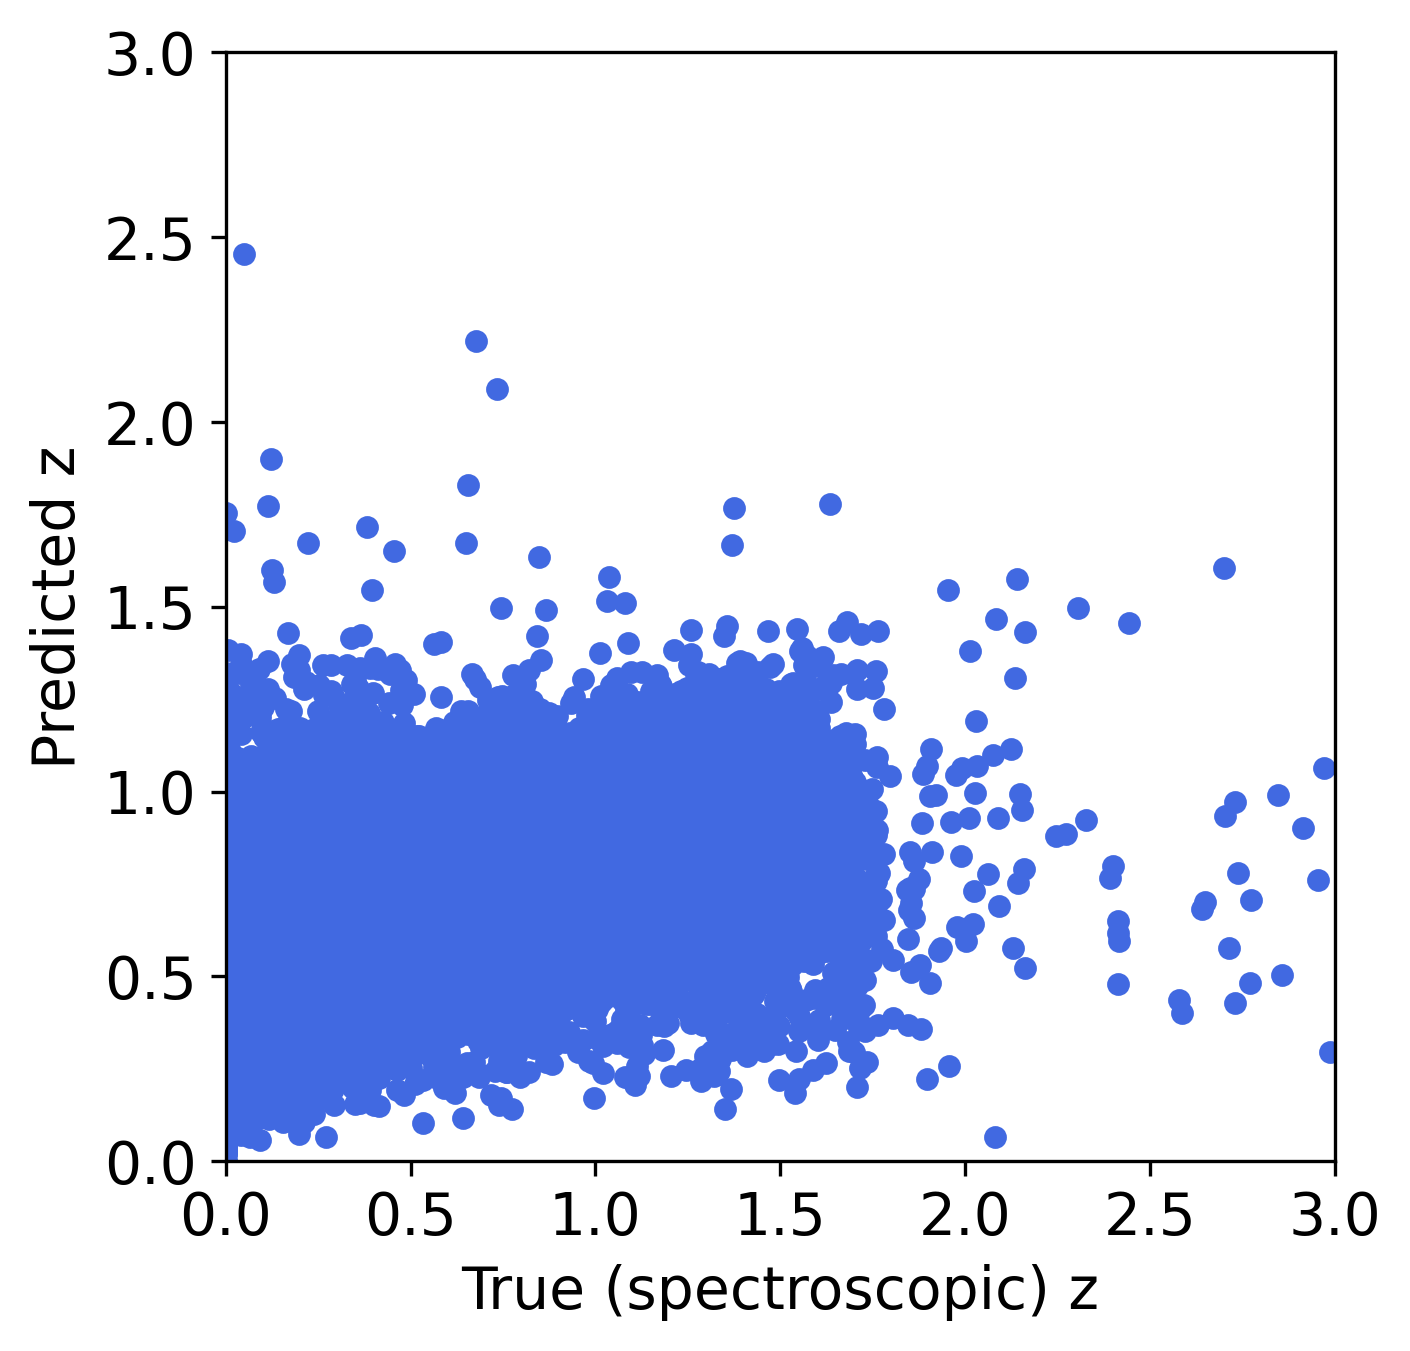

In [106]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

Esta imagen no se parece a la del paper. No hay ninguna relacion lineal como la figura del paper. Los ejes tienen valores similares, pero la distribución es distinta.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

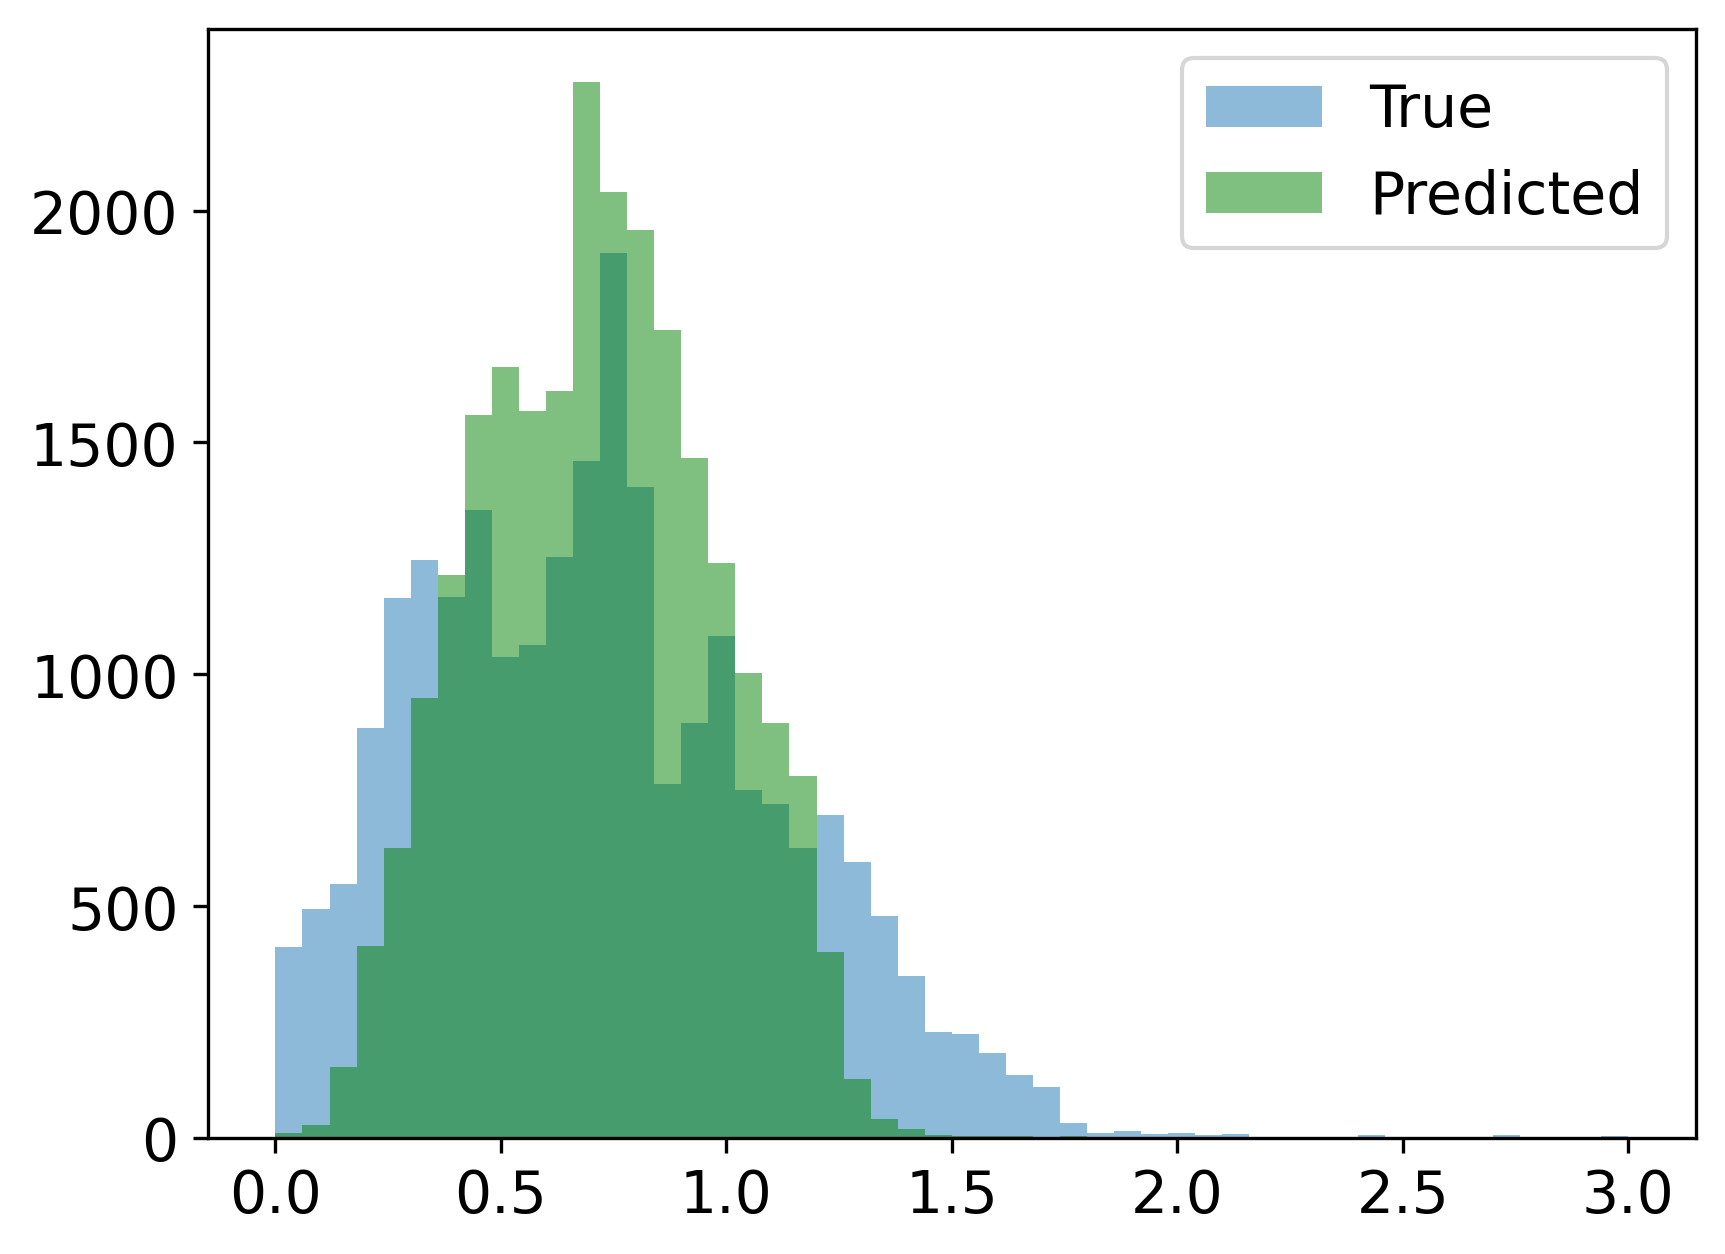

In [107]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

Se crea una funcion para reutilizarla mas adelante

In [108]:
def photoz_metrics(z_true, z_pred):
    z_true = np.asarray(z_true)
    z_pred = np.asarray(z_pred)
    dz = z_pred - z_true
    eta = np.mean(np.abs(dz) > 0.15 * (1 + z_true))
    sigma_nmad = 1.48 * np.median(np.abs(dz) / (1 + z_true))
    return eta, sigma_nmad

eta, sigma_nmad = photoz_metrics(target, ypred)
print(f"eta = {eta:.2%}")

eta = 25.69%


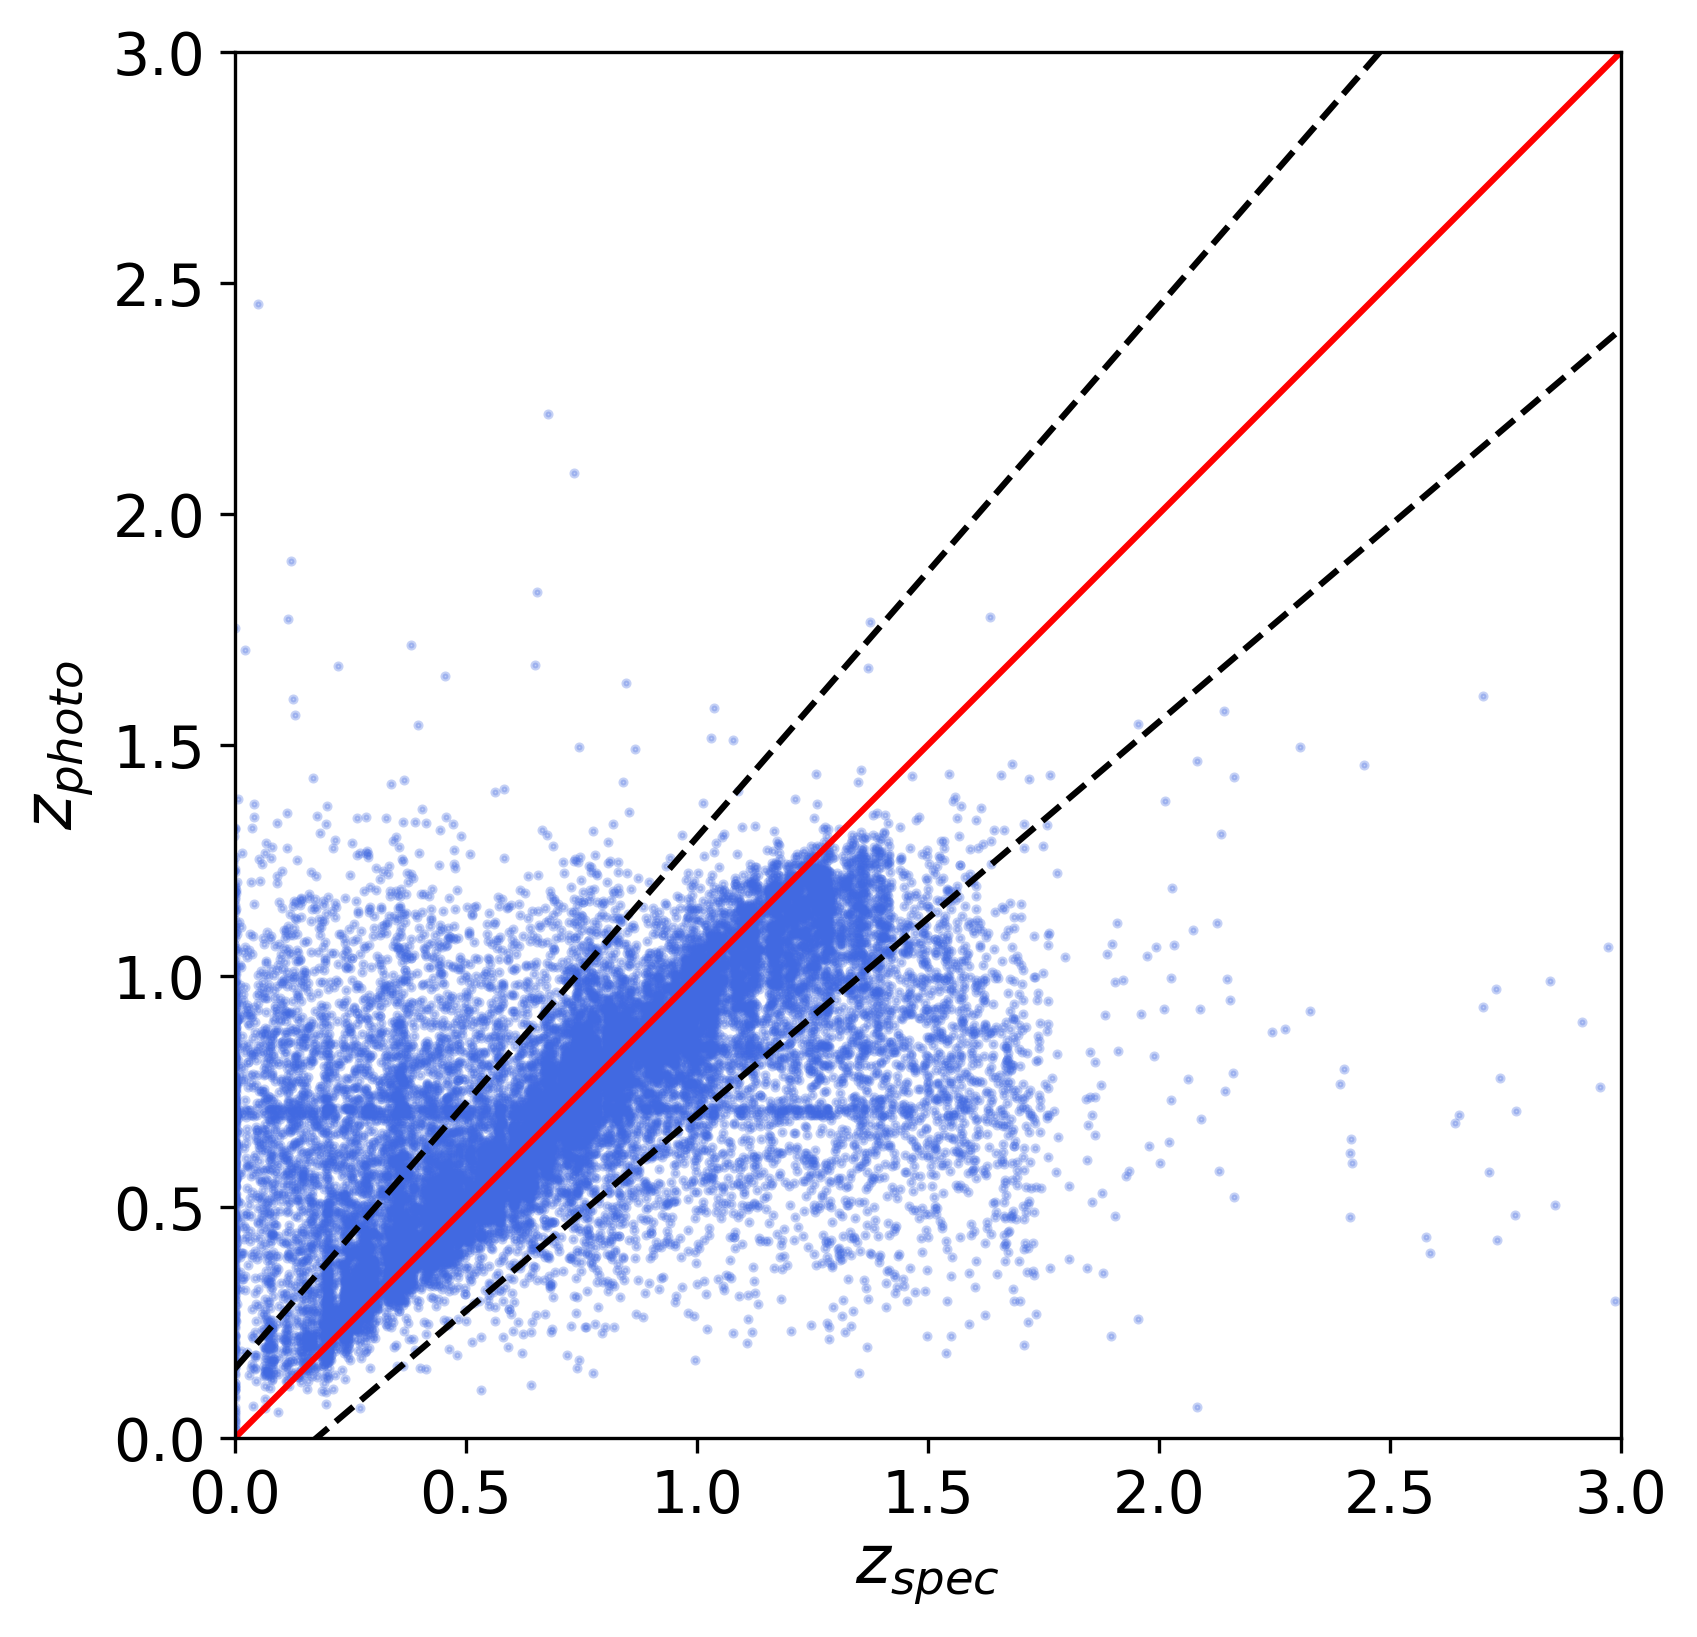

In [109]:
x = np.linspace(0, 3, 100)
plt.figure(figsize=(6, 6))
plt.scatter(target, ypred, s=2, alpha=0.3, c='royalblue')
plt.plot(x, x, 'r-')
plt.plot(x, x + 0.15 * (1 + x), 'k--')
plt.plot(x, x - 0.15 * (1 + x), 'k--')
plt.xlabel(r'$z_{spec}$')
plt.ylabel(r'$z_{photo}$')
plt.xlim(0, 3)
plt.ylim(0, 3)
plt.gca().set_aspect('equal')

y NMAD

In [ ]:
print(f"sigma_NMAD = {sigma_nmad:.2%}")

sigma_NMAD = 0.0744


En el paper en la figura 5 se tiene un eta = 6% y un sugma_NMAD = 0.0381. Nuestros valores son mucho mas altos, con eta = 60.57% y sigma_NMAD = 0.2886, por lo que hace falta optimizarlos.

### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [111]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo 

In [112]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [113]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [114]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [115]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(0.27762715338769406, 0.8763722031531694)

Se optiene scores de test ≈ 0.28 y  train ≈ 0.88. Estos son similares a los del dataset completo, así que es representativo para optimizar hiperparámetros. Se mantiene la brecha train/test, indicando varianza alta.

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [116]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [117]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100], 
              'max_leaf_nodes':[None, 100, 200]}

model = GridSearchCV(RandomForestRegressor(), parameters,
                     cv=KFold(n_splits=5, shuffle=True, random_state=10),
                     return_train_score=True, verbose=2, n_jobs=-1)
model.fit(seld, selt)

print('Best params, best score:', f"{model.best_score_:.4f}", model.best_params_)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.2s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=20, n_estimators=50; total time=   0.

Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [118]:
scores = pd.DataFrame(model.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [119]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.300210,0.031825,0.651051
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.297974,0.033252,0.725937
100,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.297678,0.033314,0.751012
184,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.296523,0.027992,0.620391
23,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split'...",0.296362,0.034230,0.665956
...,...,...,...,...
174,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.5, 'min_samples_split': 2...",-0.000296,0.000134,-0.000010
135,"{'max_features': 4, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 10...",-0.000301,0.000156,-0.000011
36,"{'max_features': None, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.000302,0.000154,-0.000011
138,"{'max_features': 4, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 20...",-0.000313,0.000182,-0.000007


### Mejoran los scores?

Para comparar con el paper, calculamos η y σ_NMAD usando los mejores hiperparámetros sobre el dataset completo.

In [120]:
ypred_best = cross_val_predict(RandomForestRegressor(**model.best_params_), features, target,
                               cv=KFold(n_splits=5, shuffle=True, random_state=10), n_jobs=-1)

zspec = np.asarray(target)
dz_best = ypred_best - zspec
eta_best = np.mean(np.abs(dz_best) > 0.15 * (1 + zspec))
sigma_nmad_best = 1.48 * np.median(np.abs(dz_best) / (1 + zspec))
print(f"eta = {eta_best:.2%}, sigma_NMAD = {sigma_nmad_best:.4f}")

eta = 25.93%, sigma_NMAD = 0.0789


Se puede ver que mejoran un poco. En el mejor modelo (max_features=4, min_samples_split=20, min_impurity_decrease=0) se obtiene un $R^2$ $\sim 0.30$ mientras que en el por defecto se tiene $\sim 0.28$. Para el train se baja de $\sim 0.88$ a $\sim 0.65$, lo que reduce el overfitting. 

Se puede ver al final que con min_impurity_decrease = 0.1 o 0.5 el R² es $\sim 0$. Esto dice que como el umbral es muy alto, el arbol casi no se divide y predice el promedio. 

Además se tiene $\eta = 26.02\%$ y $\sigma\_{NMAD} = 0.0787$ los cuales siguen estando lejos de los del paper. 

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [121]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [122]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [123]:
mags.shape

(23822, 9)

In [124]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [125]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [126]:
mags = mags[mags > -10].dropna()

In [127]:
mags.shape

(6371, 9)

In [128]:
mags = mags[mags < 90].dropna()

In [129]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [130]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [131]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [132]:
%%time
scores_new = cross_validate(RandomForestRegressor(), sel_features, sel_target,
                            cv=KFold(n_splits=5, shuffle=True, random_state=10),
                            return_train_score=True, n_jobs=-1)

CPU times: user 6.58 ms, sys: 5.26 ms, total: 11.8 ms
Wall time: 1.42 s


In [133]:
print(f"Train R2: {scores_new['train_score'].mean():.3f} ± {scores_new['train_score'].std():.3f}")
print(f"Test  R2: {scores_new['test_score'].mean():.3f} ± {scores_new['test_score'].std():.3f}")

Train R2: 0.963 ± 0.005
Test  R2: 0.746 ± 0.103


In [134]:
ypred_new = cross_val_predict(RandomForestRegressor(), sel_features, sel_target,
                              cv=KFold(n_splits=5, shuffle=True, random_state=10), n_jobs=-1)

zspec_new = np.asarray(sel_target)
dz_new = ypred_new - zspec_new
eta_new = np.mean(np.abs(dz_new) > 0.15 * (1 + zspec_new))
sigma_nmad_new = 1.48 * np.median(np.abs(dz_new) / (1 + zspec_new))
print(f"eta = {eta_new:.2%}, sigma_NMAD = {sigma_nmad_new:.4f}")

eta = 5.52%, sigma_NMAD = 0.0360


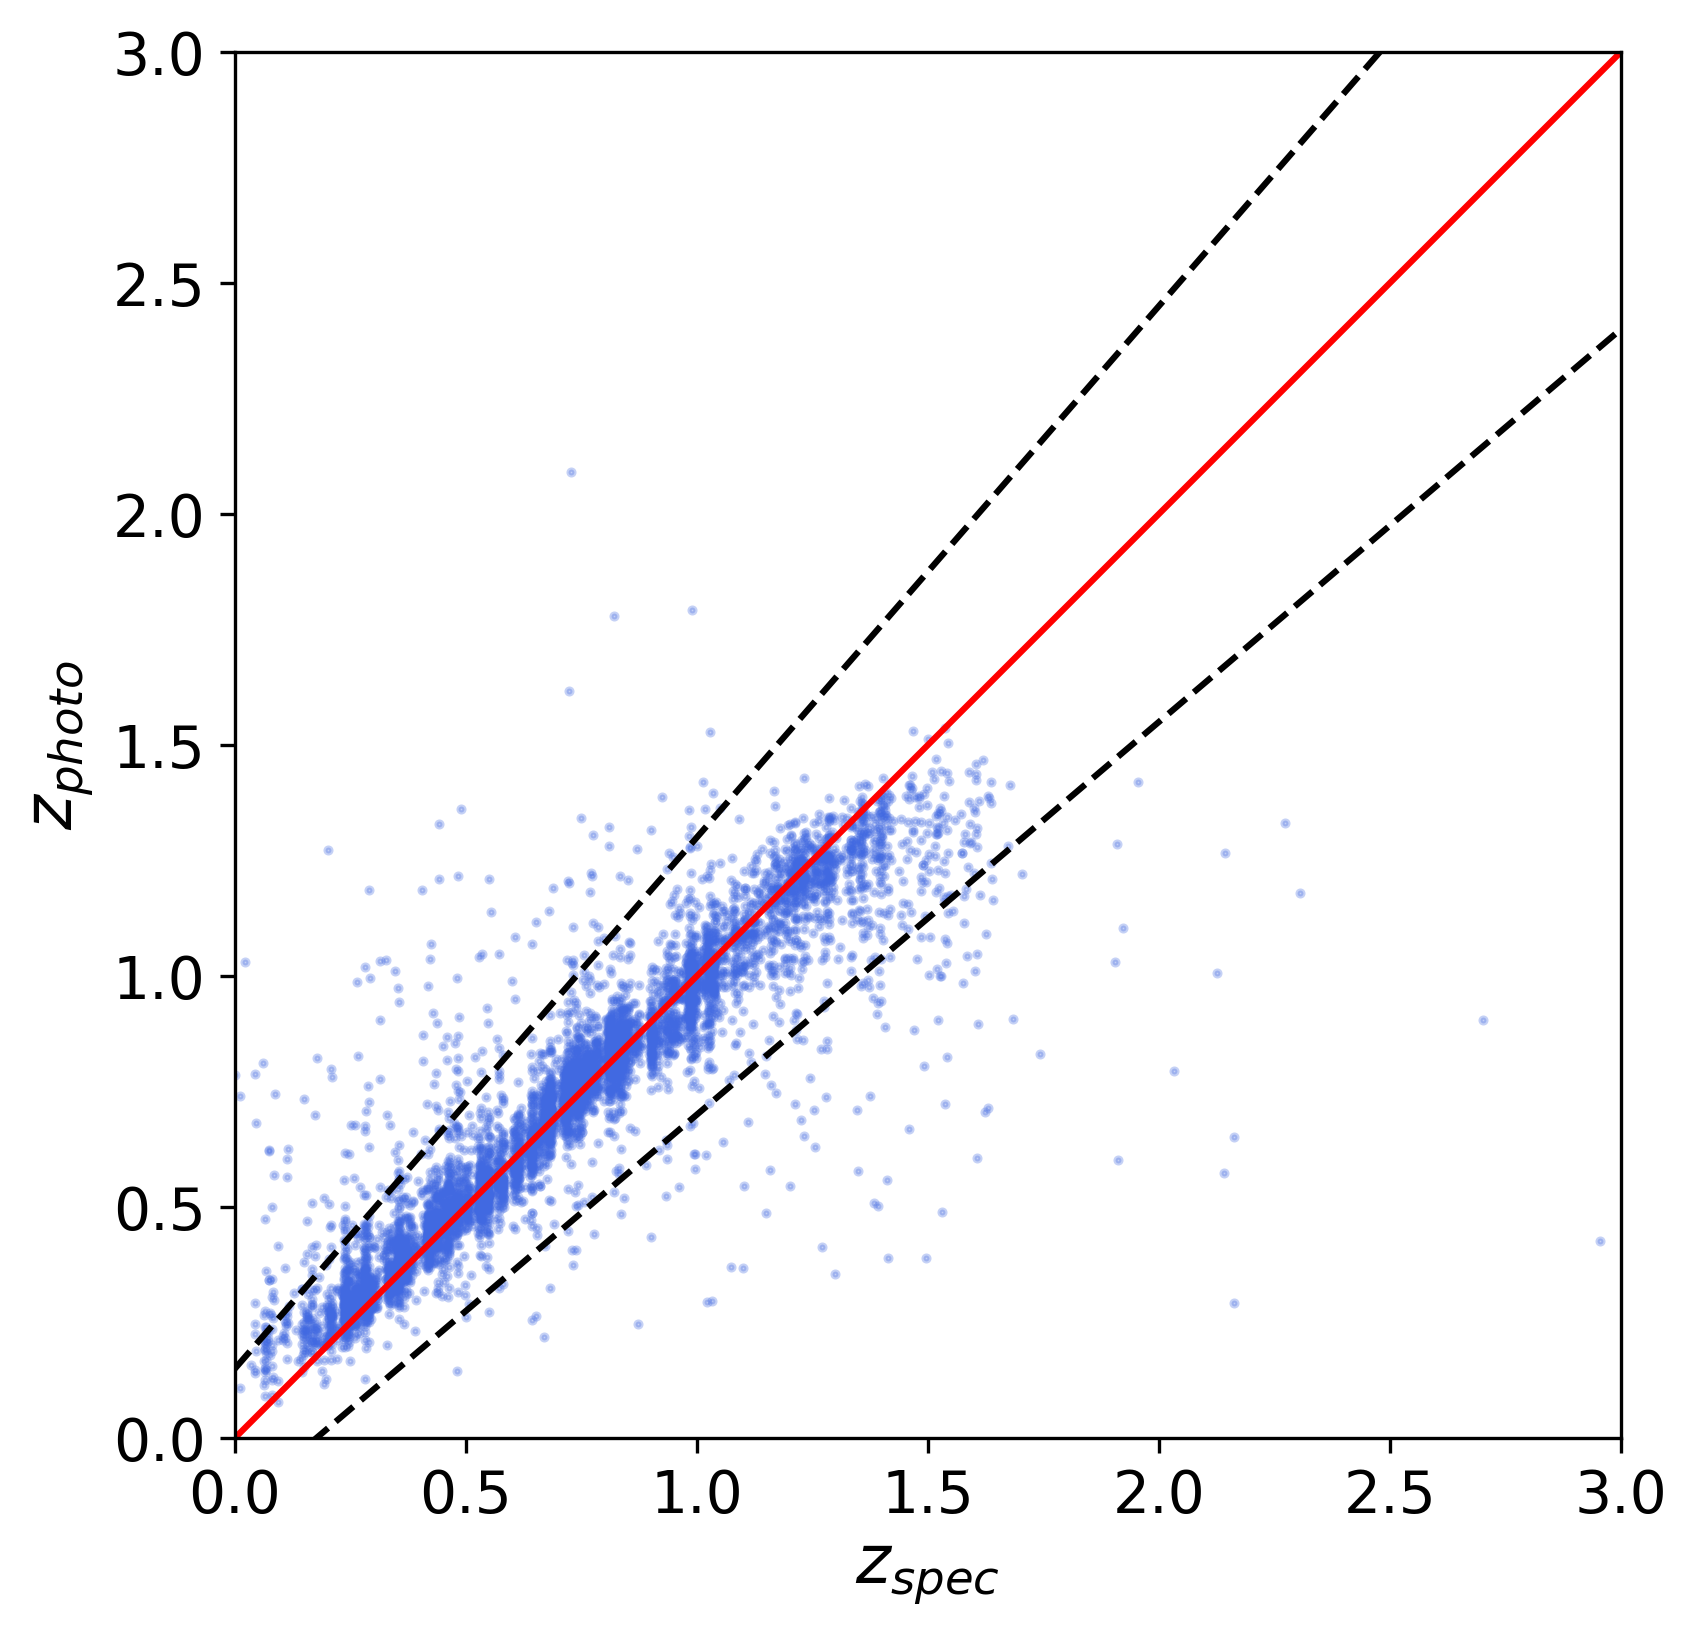

In [135]:
x = np.linspace(0, 3, 100)
plt.figure(figsize=(6, 6))
plt.scatter(zspec_new, ypred_new, s=2, alpha=0.3, c='royalblue')
plt.plot(x, x, 'r-')
plt.plot(x, x + 0.15 * (1 + x), 'k--')
plt.plot(x, x - 0.15 * (1 + x), 'k--')
plt.xlabel(r'$z_{spec}$')
plt.ylabel(r'$z_{photo}$')
plt.xlim(0, 3)
plt.ylim(0, 3)
plt.gca().set_aspect('equal')

### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



Podemos cer ahora que nuestros valores mejoran mucho. Para el test $R^2$ = $0.746$ $\pm$ $0.103$, el cual es mucho que mejor que el del modelo por defecto ($\sim 0.28$). Ademas se tiene un $\eta = 5.52 \%$ y un $\sigma\_{NMAD} = 0.036$ los cuales son mucho mas parecidos a los del paper. La imagen tambien es mucho mas parecida. 
Estos resultados son comparables al campo Wide del paper ($6.00\%$, $0.0381$), pero peores que el campo Deep ($4.54\%$, $0.0174$). 

Todavía exite un overfitting ya que para train se tiene $R^2$ = $0.963$.

Para mejorar el modelo se decide usar coores en vez de mangitudes para entrenar el modelo. Es lo que se hace en la sección 7 del paper. Los colores son independientes del brillo total y la distancia de la galaxia y nos permite medir la forma del espectro, el cual se desplaza con el redshift. Además se mantiene la magnitud i para tener informacion del brillo. 

In [136]:
colors = pd.DataFrame({'u-g': sel_features['u_apercor'] - sel_features['g_apercor'],
                       'g-r': sel_features['g_apercor'] - sel_features['r_apercor'],
                       'r-i': sel_features['r_apercor'] - sel_features['i_apercor'],
                       'i-z': sel_features['i_apercor'] - sel_features['z_apercor'],
                       'z-y': sel_features['z_apercor'] - sel_features['y_apercor'],
                       'i': sel_features['i_apercor']})
colors.head()

,u-g,g-r,r-i,i-z,z-y,i
1251,0.264811,0.457447,0.611094,0.385268,0.196675,22.911041
1253,0.572953,0.992500,1.049899,0.567258,0.055055,21.873752
1261,1.900066,1.508042,0.677430,0.326138,0.048586,20.788420
1271,0.190411,0.447442,0.685087,0.216758,-0.123037,23.206102
1272,0.253733,0.412146,0.740102,0.425541,0.250175,22.235199


In [137]:
scores_col = cross_validate(RandomForestRegressor(), colors, sel_target,
                            cv=KFold(n_splits=5, shuffle=True, random_state=10),
                            return_train_score=True, n_jobs=-1)
print(f"Train R2: {scores_col['train_score'].mean():.3f} ± {scores_col['train_score'].std():.3f}")
print(f"Test  R2: {scores_col['test_score'].mean():.3f} ± {scores_col['test_score'].std():.3f}")

Train R2: 0.972 ± 0.002
Test  R2: 0.814 ± 0.079


In [138]:
ypred_col = cross_val_predict(RandomForestRegressor(), colors, sel_target,
                              cv=KFold(n_splits=5, shuffle=True, random_state=10), n_jobs=-1)

dz_col = ypred_col - zspec_new
eta_col = np.mean(np.abs(dz_col) > 0.15 * (1 + zspec_new))
sigma_nmad_col = 1.48 * np.median(np.abs(dz_col) / (1 + zspec_new))
print(f"eta = {eta_col:.2%}, sigma_NMAD = {sigma_nmad_col:.4f}")

eta = 3.65%, sigma_NMAD = 0.0163


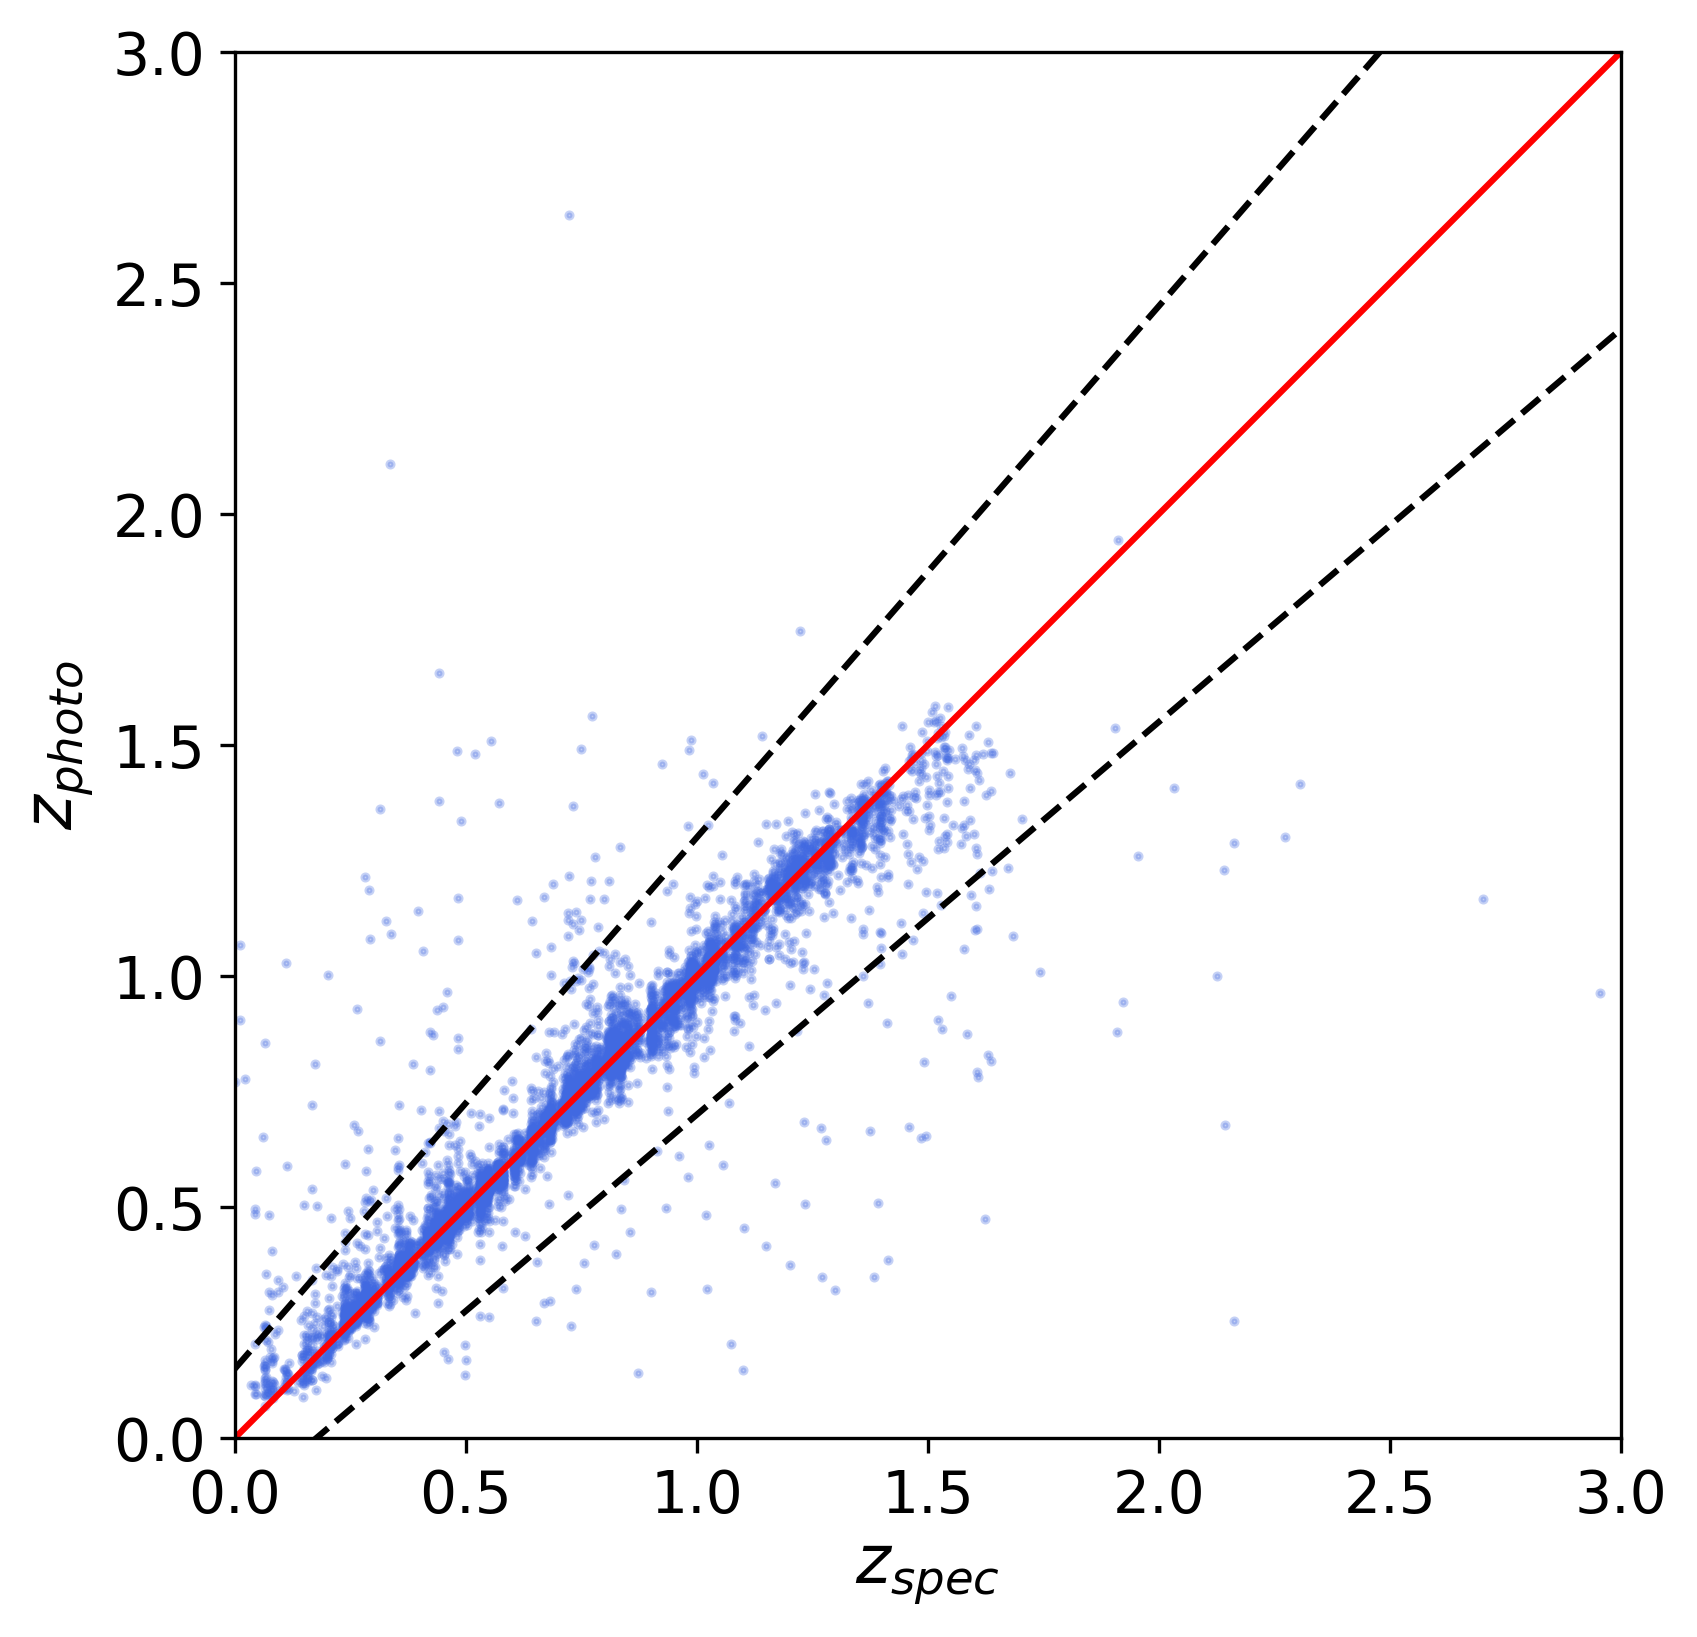

In [139]:
x = np.linspace(0, 3, 100)
plt.figure(figsize=(6, 6))
plt.scatter(zspec_new, ypred_col, s=2, alpha=0.3, c='royalblue')
plt.plot(x, x, 'r-')
plt.plot(x, x + 0.15 * (1 + x), 'k--')
plt.plot(x, x - 0.15 * (1 + x), 'k--')
plt.xlabel(r'$z_{spec}$')
plt.ylabel(r'$z_{photo}$')
plt.xlim(0, 3)
plt.ylim(0, 3)
plt.gca().set_aspect('equal')

Usando los clores y la magnitud i como featires, como en la seccción 7 de paper, se tiene una gran mejora en los resultados. El $R^2$ = $0.814$, el $\eta = 3.65\%$ y el $\sigma_{NMAD} \ = 0.0163$, los cuales son incluso mejor que los del paper en el campo deep($4.54\%$ y $0.0174$).